In [223]:
# INPUT: experiment_name
# OUTPUT: - Goes into the experiment folder
#         - Fits the VM and the FTVM functions
#         - Calculates all their SSIs

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
import os
import pickle5 as pickle
from scipy.optimize import curve_fit

import import_ipynb
import ipynb.fs.full.ssiProjectModule as ssiMod

import importlib as imp
imp.reload(ssiMod)

to_save=False

from matplotlib import gridspec

In [1]:
# this code takes the datam fits VM and FTVM functions (unconstrained parameters)
# it collects all the parameters in an array, as well as s and g in separate arrays (s_arr and g_arr)
# it calculates the RMSE between data and fit
# it calculates the SSI from both fit and raw data
# it generates an array containing 90 elements, w each being (a,b) = (exp_number, cell_index), for bookkeeping
# it plots the raw data TCs and the fitted TCs over them


main_dir = '/home/cparis/00PhD/'
raw_data_dir = main_dir+'Raw Data/'
plt.close()

upper_s_lim = 1
dat_dir_out = main_dir+f'Constrained s/s_max={upper_s_lim}/'


if not os.path.isdir(dat_dir_out):
    os.mkdir(dat_dir_out)

s_arr = np.array([])
g_arr = np.array([])
mse_arr = np.array([])
dsi_arr = np.array([])

stim = np.arange(0, 360, 10)

exp_idx_arr = np.array([])

thr = 3.5

all_params = np.array([])
all_fwhm = np.array([])


all_data = np.array([])
all_data_std = np.array([])
all_fits = np.array([])

for experiment_number in range(1,8,1):
    experiment_name = f'Exp{experiment_number}'
    dat_dir = main_dir + experiment_name +'/'
    props = {'boxstyle':'round', 'edgecolor':'white', 'facecolor':'white', 'alpha':0}
    

#     datanfits = {}
    datanfits = dict(np.load(main_dir+'Analysis of '+experiment_name+'.npz'))
    all_vm_fit_parameters = []
    all_ftvm_fit_parameters = []
    mse_ftvm_fit = []
    mse_vm_fit = []
    
    #datanfits contains:
    #     - calculated mean tuning curves + their calculated standard deviations + its SSI
    #     - fitted von mises function + fit parameters + its SSI
    #     - fitted flat-topped von mises function + fit parameters + its SSI
    #     - mean square errors between the measured TCs and the 2 fits

    with open(raw_data_dir+experiment_name+'.pkl', 'rb') as rick:
        experimental_data = pickle.load(rick)

    n_repetitions, n_th, n_cells = experimental_data['spikeCounts'].shape            #repetitions , stimuli , cells

    exps = experimental_data['expIdx']
    mean_tcs = np.array([np.mean(experimental_data['spikeCounts'][:,:,k],0) \
                         for k in range(n_cells)])    # i,j,k = repetitions, theta, cells
    mean_tcs_std = np.array([np.std(experimental_data['spikeCounts'][:,:,k],0) for k in range(n_cells)])
    mean_tcs_std[mean_tcs_std==0.] = 1e-10

    datanfits['mean_tcs'] = mean_tcs
    datanfits['mean_tcs_std'] = mean_tcs_std

    guess_th = np.pi
    for idx in range(len(mean_tcs)):
        max_a=np.sum(mean_tcs[idx])
        max_tc = np.max(mean_tcs[idx])
        one_vm_fit_parameters, _ = curve_fit(ssiMod.VON_MISES, stim, mean_tcs[idx], \
                                             p0 = (max_a, 0, upper_s_lim/2, 0), \
                                             bounds = ((1,       -180,1e-5,        0),\
                                                       (2*max_a,180,upper_s_lim, max_tc)))
        all_vm_fit_parameters += [one_vm_fit_parameters] 

        ftvm_parameter_guess = np.append(one_vm_fit_parameters, 0)     #guess g is 0.     parameters = (a, th_0, s, baseline, g)
        one_ftvm_fit_parameters, _ = curve_fit(ssiMod.FLAT_TOPPED_VON_MISES, stim, mean_tcs[idx], \
                                               p0 = ftvm_parameter_guess, \
                                               bounds = ((1,        -190, 1e-5,           0,       -180),\
                                                         (2*max_a, 190, upper_s_lim,    max_tc,  180)))

        all_ftvm_fit_parameters += [one_ftvm_fit_parameters]

    all_vm_fit_parameters = np.array([el for el in all_vm_fit_parameters])
    all_ftvm_fit_parameters = np.array([np.array(el) for el in all_ftvm_fit_parameters])
    
    all_params  = np.concatenate((all_params, all_ftvm_fit_parameters)) if all_params.size \
                    else all_ftvm_fit_parameters
    
    fwhm_arr = np.array([ssiMod.FWHM(el) for el in all_ftvm_fit_parameters])
    all_fwhm  = np.concatenate((all_fwhm, fwhm_arr)) if all_fwhm.size \
                    else fwhm_arr
    
    
    s_arr = np.concatenate((s_arr, all_ftvm_fit_parameters[:,2])) if s_arr.size else all_ftvm_fit_parameters[:,2]
    g_arr = np.concatenate((g_arr, all_ftvm_fit_parameters[:,-1])) if g_arr.size else all_ftvm_fit_parameters[:,-1]
    
    
    
#     get fits from found parameters
    vm_fit = np.array([ssiMod.VON_MISES(stim, *pars) for pars in all_vm_fit_parameters])
    ftvm_fit = np.array([ssiMod.FLAT_TOPPED_VON_MISES(stim, *pars) for pars in all_ftvm_fit_parameters])
    
    
    all_data = np.concatenate((all_data, mean_tcs)) if all_data.size else mean_tcs
    all_data_std = np.concatenate((all_data_std, mean_tcs_std)) if all_data_std.size else mean_tcs_std
    all_fits = np.concatenate((all_fits, ftvm_fit)) if all_fits.size else ftvm_fit
    
    
#     get RMSE between data and fits
    mse_vm_fit = np.sqrt(np.mean((mean_tcs-vm_fit)**2, axis=1))
    mse_ftvm_fit = np.sqrt(np.mean((mean_tcs-ftvm_fit)**2, axis=1))
    
    
    
    c_s = np.array([(np.sum(el*np.cos(np.deg2rad(stim)))/np.sum(el), np.sum(el*np.sin(np.deg2rad(stim)))/np.sum(el)) for el in mean_tcs])
    r = np.around(np.sqrt(np.sum(c_s**2, axis = 1)), 3)
    dsi_arr = np.concatenate((dsi_arr, r)) if dsi_arr.size else r

    
    exp_idx_arr = np.concatenate((exp_idx_arr, np.concatenate((np.full(len(mean_tcs), experiment_number)[:,None], \
                                                               np.arange(len(mean_tcs))[:,None]), axis = 1)), axis=0) if exp_idx_arr.size \
                    else np.concatenate((np.full(len(mean_tcs), experiment_number)[:,None], \
                                                               np.arange(len(mean_tcs))[:,None]), axis = 1)
    
    
    mse_arr = np.concatenate((mse_arr, mse_ftvm_fit)) if mse_arr.size else mse_ftvm_fit

    ssi_raw_data = ssiMod.GET_SSI_LOOP(np.copy(mean_tcs))
    ssi_vm_fit = ssiMod.GET_SSI_LOOP(np.copy(vm_fit))
    ssi_ftvm_fit = ssiMod.GET_SSI_LOOP(np.copy(ftvm_fit))
    
#     print(np.corrcoef(all_ftvm_fit_parameters[:,2], all_ftvm_fit_parameters[:,-1])[0,1])
    datanfits['vm_fit_real_data'] = vm_fit
    datanfits['vm_fit_parameters'] = all_vm_fit_parameters
    datanfits['ftvm_fit_real_data'] = ftvm_fit
    datanfits['ftvm_fit_parameters'] = all_ftvm_fit_parameters
    datanfits['ssi_raw_data'] = ssi_raw_data
    datanfits['ssi_vm_fit'] = ssi_vm_fit
    datanfits['ssi_ftvm_fit'] = ssi_ftvm_fit
    datanfits['mse_vm_fit'] = mse_vm_fit
    datanfits['mse_ftvm_fit'] = mse_ftvm_fit
    
    np.savez(dat_dir_out+f'Analysis of {experiment_name}.npz', **datanfits)
    
    for i, el in enumerate(mean_tcs):
        if mse_ftvm_fit[i] <= thr: c = 'green'
        else: c = 'red'
        plt.figure()
        plt.plot(stim, el, label = f'({experiment_number}, {i})', color = c)
        plt.plot(stim, ftvm_fit[i], linestyle = '--')
        plt.ylim(top =100)
        plt.legend()

#     fig = plt.figure(figsize = (5*len(mean_tcs), 5))
#     gs = gridspec.GridSpec(1, len(mean_tcs))
#     for i, el in enumerate(mean_tcs):
#         ax = fig.add_subplot(gs[0,i])
#         ax.errorbar(stim, el, yerr=mean_tcs_std[i], capsize = 5)

#         ax.plot(stim, ftvm_fit[i], color = 'r', linestyle = 'dashed')
#     plt.savefig(dat_dir_out+f'Cell fits_{experiment_name}-{upper_s_lim}.pdf', bbox_inches = 'tight')


# all_datanfits = {}
# all_datanfits['mean_tcs'] = all_data
# all_datanfits['mean_tcs_std'] = all_data_std
# all_datanfits['ftvm_fit_real_data'] = all_fits
# all_datanfits['dsi'] = dsi_arr
# all_datanfits['fwhm'] = all_fwhm
# all_datanfits['exp_idx_array'] = exp_idx_arr
# all_datanfits['ftvm_fit_parameters'] = all_params

NameError: name 'plt' is not defined

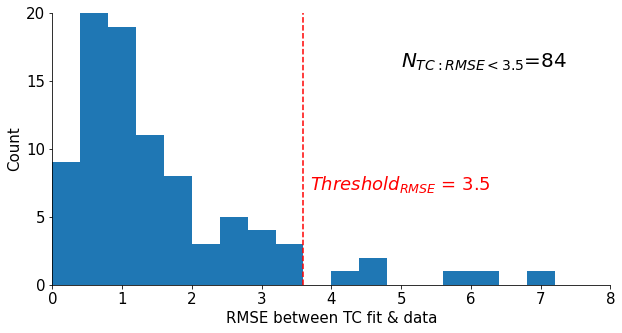

In [903]:
#  Histogram of all RMSE = E[ (TC_fit -TC_data )**2 ]
nbins = 20

plt.figure(figsize = (10,5))
plt.hist(mse_arr, range = (0,8),bins=nbins)
plt.axvline(3.6, color = 'red', linestyle = 'dashed')
plt.text(3.7, 7, r'$Threshold_{RMSE}$ = 3.5', color = 'red', size = 18)
plt.xlim(0, 8)
plt.ylim(0,20)
plt.xticks(np.arange(0,9,1))
plt.yticks(np.arange(0,21,5))
plt.tick_params('both', labelsize = 15)
plt.xlabel('RMSE between TC fit & data', size = 15)
plt.ylabel('Count', size = 15)
plt.text(5, 16, r'$N_{TC:RMSE<3.5}$='+f'{np.count_nonzero(mse_arr<3.5)}', size = 20)
plt.savefig(main_dir+f'All RMSE of TC fit vs data (bins={nbins}).png', bbox_inches = 'tight')

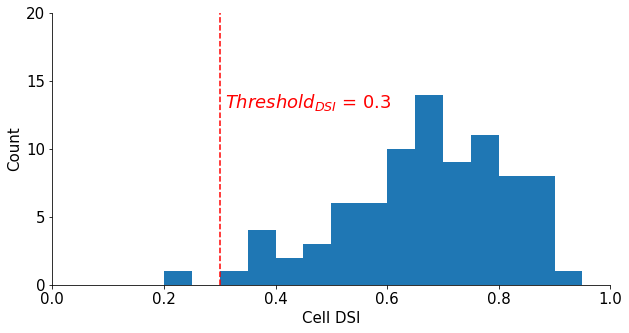

In [904]:
# Histogram of DSI (Direction Selectivity Index) for cells w RMSE <= 3.5

bad_tc_idx = np.where(mse_arr>=3.5)[0]
nbins = 20

plt.figure(figsize = (10,5))
plt.hist(dsi_arr[np.where(mse_arr<3.5)[0]], range = (0,1), bins = nbins)
plt.tick_params('both', labelsize = 15)
plt.xlim(0,1)
plt.xticks(np.arange(0,1.1,0.2))
plt.ylim(0,20)
plt.yticks(np.arange(0,21,5))
plt.xlabel('Cell DSI', size = 15)
plt.ylabel('Count', size = 15)

plt.axvline(0.3, color = 'red', linestyle = 'dashed')
plt.text(0.31, 13, r'$Threshold_{DSI}$ = 0.3', color = 'red', size = 18)
plt.savefig(main_dir+f'Cell DSI (bins={nbins}).png', bbox_inches = 'tight')

[ 3  7 13 27 30 39 74]
(36,)
[1 3]
[1 7]
[ 1 13]
[3 0]
[3 3]
[ 3 12]
[6 8]


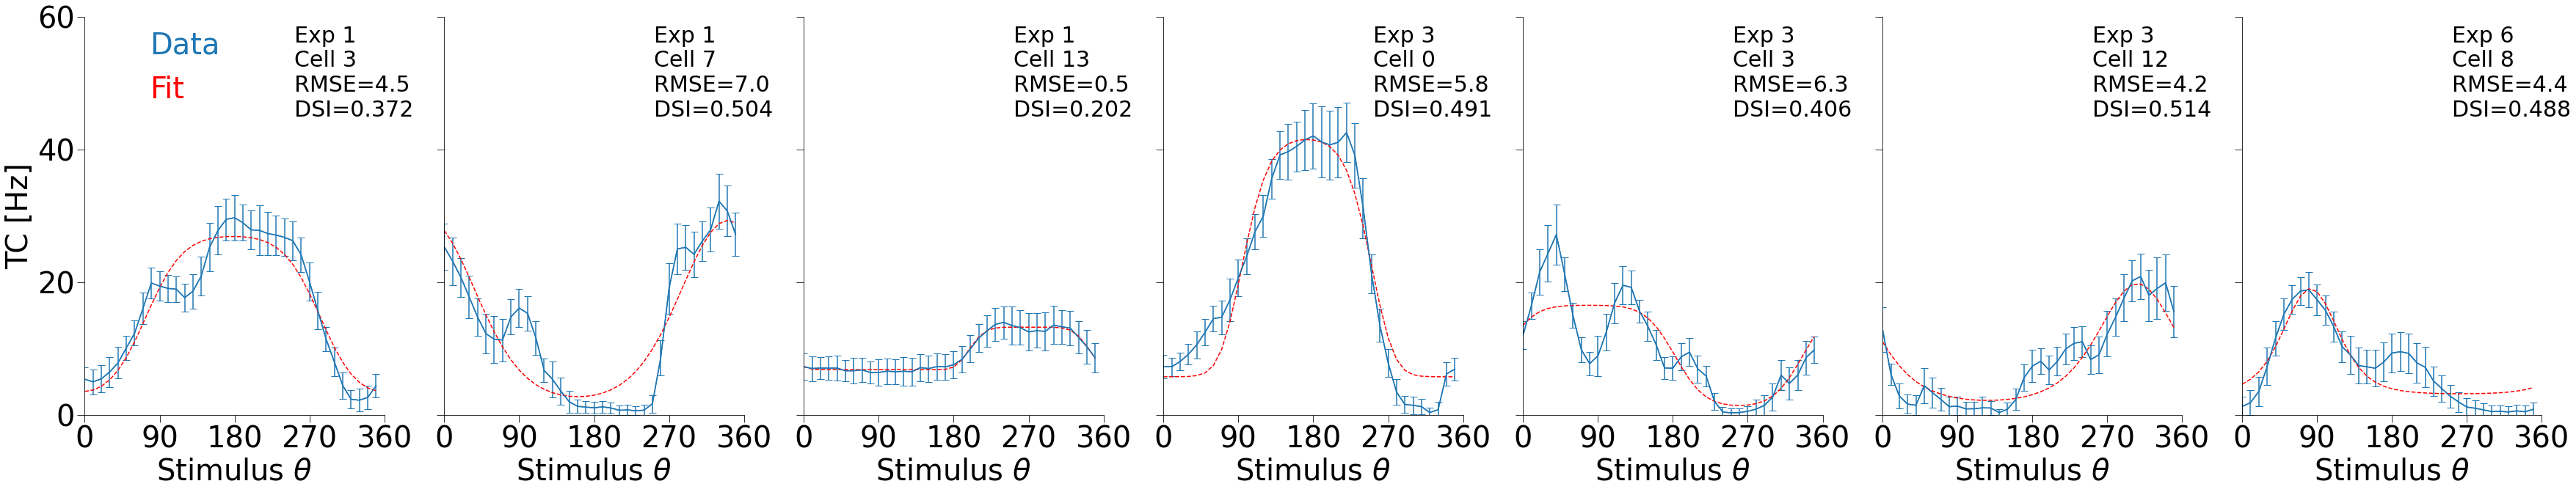

In [905]:
# Plots of cells that are eliminated w criteria RMSE <= 3.5 AND DSI >= 0.3

bad_tc_idx = np.unique(np.append(np.where(mse_arr>=3.5)[0], np.where(dsi_arr<=0.3)[0]))
print(bad_tc_idx)
fig = plt.figure(figsize = (bad_tc_num*10, 10))
gs = gridspec.GridSpec(1, len(bad_tc_idx))
print(all_data_std[bad_tc_idx[0]].shape)


for i,idx in enumerate(bad_tc_idx):
    lab = exp_idx_arr[idx]
    print(lab)
    ax = fig.add_subplot(gs[0,i])
    ax.set_xlabel(r'Stimulus $\theta$', size = 40)
    ax.errorbar(stim, all_data[idx]/1.6, yerr = all_data_std[idx]/1.6, capsize = 5)
    ax.plot(stim, all_data[idx]/1.6, color = 'tab:blue', label = 'Data')
    ax.plot(stim, all_fits[idx]/1.6, color = 'red', linestyle = 'dashed', label = 'Fit')
    
    ax.tick_params('both', labelsize = 40, size = 10)
    ax.set_xticks(np.arange(0, 361, 90))
    if i==0: 
        ax.set_yticks(np.arange(0, 61, 20))
        ax.legend(handlelength = 0, labelcolor = 'linecolor', frameon = 0, loc = (0.1, 0.75), fontsize = 40)
        ax.set_ylabel('TC [Hz]', size = 40)
    else: 
        ax.set_yticks(np.arange(0, 61, 20))
        ax.set_yticklabels(['' for _ in np.arange(0, 61, 20)])
    ax.text(0.7, 0.75, f'Exp {lab[0]}\nCell {lab[1]}\nRMSE={np.around(mse_arr[idx],1)}\nDSI={np.around(dsi_arr[idx],3)}', color = 'black', \
            transform = ax.transAxes, size = 30)
    ax.set_xlim(0,360)
    ax.set_ylim(0,60)
plt.savefig(main_dir+'TCs of eliminated cells.png', bbox_inches = 'tight')

In [924]:
print(exp_idx_arr[all_fwhm[:,1]>180])
ro = 0.95
print(2*np.rad2deg(np.arccos(2*ro-1)))
all_datanfits['good_cell_idxs'] = good_tc_idx

# np.savez(main_dir+'All_datanfits.npz', **all_datanfits)

[[ 1  3]
 [ 1 13]
 [ 2  3]
 [ 3  3]]
51.68386552633428


[1.e-04 1.e-02 1.e+00 2.e+01 1.e+02]


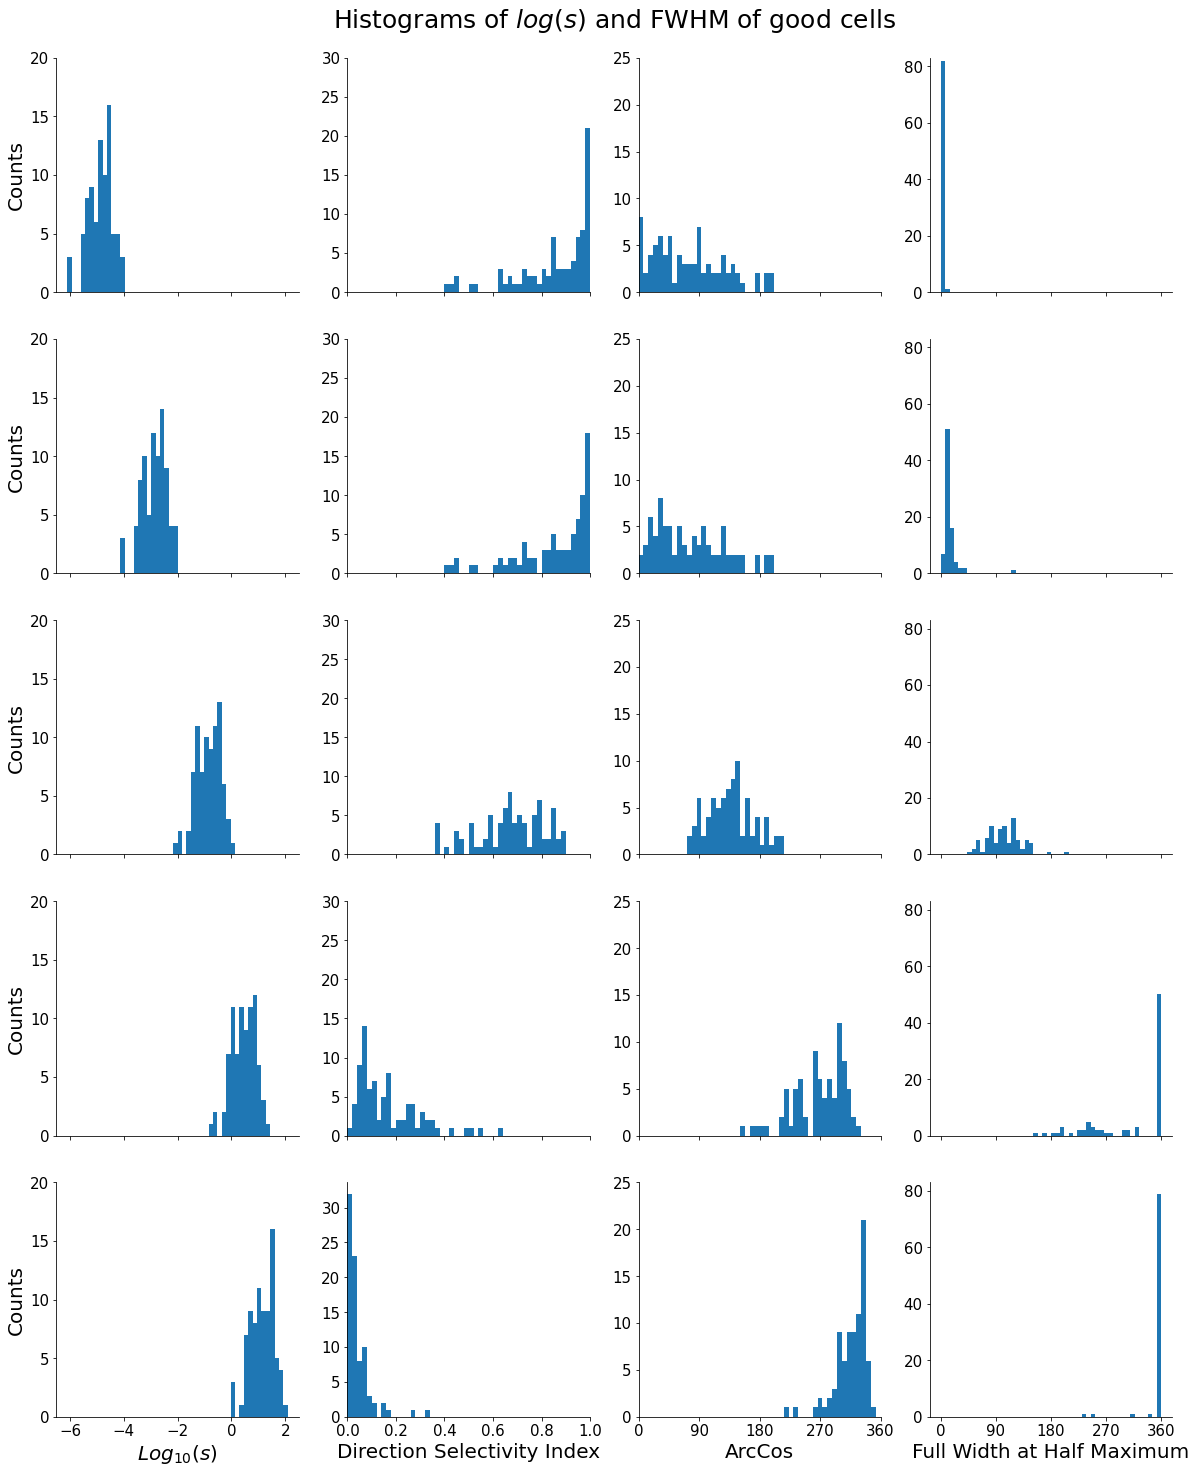

In [1025]:
nbins = 50
multipliers = np.sort(np.append(np.logspace(-4,2,4), 20))
print(multipliers)
variable_s_fwhms = np.array([])
variable_s = np.array([])
variable_dsi=np.array([])
for m in multipliers:
    changed_params = np.copy(all_params[good_tc_idx])
    changed_params[:,2] *= m
    tcs = np.array([ssiMod.FTVM(stim, *pars) for pars in changed_params])
    c_s = np.array([(np.sum(el*np.cos(np.deg2rad(stim)))/np.sum(el), np.sum(el*np.sin(np.deg2rad(stim)))/np.sum(el)) for el in tcs])
    r = np.array([np.sqrt(np.sum(c_s**2, axis = 1))])    
    variable_dsi = np.concatenate((variable_dsi, r)) if variable_dsi.size else r
    
    variable_s = np.concatenate((variable_s, np.array([changed_params[:,2]]))) if variable_s.size else np.array([changed_params[:,2]])
    new_fwhm_arr = np.array([[ssiMod.FWHM(el)[1] for el in changed_params]])
    variable_s_fwhms = np.concatenate((variable_s_fwhms, new_fwhm_arr)) if variable_s_fwhms.size else new_fwhm_arr

fig = plt.figure(figsize = (20, 5*len(multipliers)))
gs = gridspec.GridSpec(len(multipliers), 4)
plt.title(r'Histograms of $log(s)$ and FWHM of good cells', size = 25, pad = 30)
plt.axis('off')
for i in range(len(multipliers)):
    ax = fig.add_subplot(gs[i, 0])
    ax1 = fig.add_subplot(gs[i, 3])
    ax2 = fig.add_subplot(gs[i, 1])
    ax3 = fig.add_subplot(gs[i, 2])
    
    ax.hist(np.log10(variable_s[i]), range=(-6.1, 2.1), bins = nbins)
    ax1.hist(variable_s_fwhms[i], range=(0,360), bins = nbins)
    ax2.hist(variable_dsi[i], range=(0,1), bins = nbins)
    ax3.hist(2*np.rad2deg(np.arccos(2*variable_dsi[i]-1)), range=(0,360), bins = nbins)
    
    ax.set_xticks(np.arange(-6,3, 2))
    ax1.set_xticks(np.arange(0,361, 90))
    ax2.set_xticks(np.arange(0,1.1, 0.2))
    ax3.set_xticks(np.arange(0,361, 90))
    
    
    ax.set_ylabel('Counts', size = 20)
    
    ax.set_yticks(np.arange(0,21,5))
    ax.tick_params('both', labelsize = 15)
    ax1.tick_params('both', labelsize = 15)
    ax2.tick_params('both', labelsize = 15)
    ax3.tick_params('both', labelsize = 15)
    
    ax.set_ylim(0,20)
    ax1.set_ylim(0,83)
    ax2.set_xlim(0,1)
    ax3.set_xlim(0,361)
    
    ax2.set_yticks(np.arange(0,31, 5))
    ax3.set_yticks(np.arange(0,26, 5))
    
    
    if i==len(multipliers)-1:
        ax.set_xlabel(r'$Log_{10}(s)$', size = 20)
        ax1.set_xlabel(r'Full Width at Half Maximum', size = 20)
        ax2.set_xlabel(r'Direction Selectivity Index', size = 20)
        ax3.set_xlabel(r'ArcCos', size = 20)

    else:
        ax.set_xticklabels([])
        ax1.set_xticklabels([])  
        ax2.set_xticklabels([])
        ax3.set_xticklabels([])


plt.savefig(main_dir+f'Histogram of log_s and FWHM (bins={nbins}).png', bbox_inches = 'tight')

In [1024]:
print(multipliers)

[1.e-04 1.e-02 1.e+00 2.e+01 1.e+02]


[0.359 0.677 0.474 0.518 0.572 0.518 0.715 0.707 0.613 0.595 0.639 0.517
 0.589 0.635 0.726 0.853 0.815 0.474 0.824 0.738 0.597 0.741 0.646 0.839
 0.678 0.695 0.656 0.552 0.63  0.8   0.816 0.718 0.672 0.766 0.648 0.677
 0.792 0.778 0.803 0.875 0.792 0.886 0.885 0.771 0.64  0.68  0.601 0.513
 0.542 0.381 0.443 0.764 0.789 0.845 0.692 0.647 0.543 0.464 0.678 0.343
 0.854 0.738 0.874 0.722 0.857 0.678 0.68  0.442 0.586 0.697 0.36  0.652
 0.676 0.9   0.362 0.753 0.626 0.776 0.792 0.785 0.714 0.875 0.848]
[74  5 26 19 82]


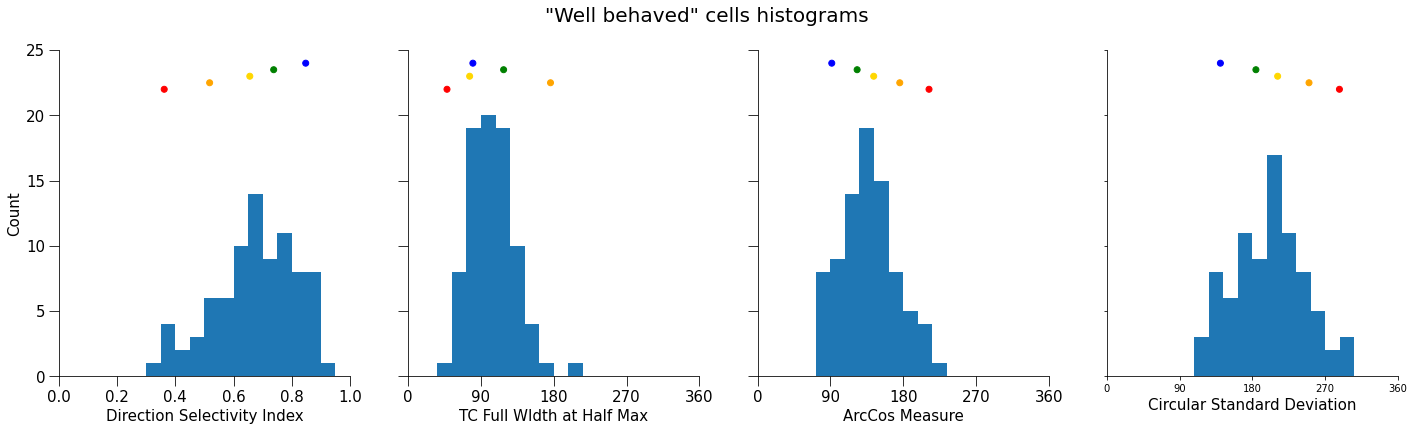

In [912]:
# Histogram of FWHM and Circular STD of cells that satisfy criteria RMSE <= 3.5 AND DSI >= 0.3

example_idxs = np.argsort(dsi_arr[good_tc_idx])[np.array([3,13,33,53,73])]
print(dsi_arr[good_tc_idx])
print(example_idxs)

nbins = 20
cvar_alternative = 2*np.rad2deg(np.arccos(2*dsi_arr-1))
cstd = 360*np.sqrt(1.- dsi_arr)

bad_tc_idx = np.unique(np.append(np.where(mse_arr>=3.5)[0], np.where(dsi_arr<=0.3)[0]))
good_tc_idx = np.setdiff1d(np.arange(len(all_data)), bad_tc_idx)


fig = plt.figure(figsize = (24,6))
gs = gridspec.GridSpec(1,4)

fig.suptitle('"Well behaved" cells histograms', size = 20)

ax0 = fig.add_subplot(gs[0,0]) 
ax = fig.add_subplot(gs[0,1])
ax1 = fig.add_subplot(gs[0,2])
ax2 = fig.add_subplot(gs[0,3])

ax0.hist(dsi_arr[good_tc_idx], range = (0,1), bins = nbins)
ax0.set_xlim(0,1)
ax0.set_ylim(0,25)
ax0.set_xticks(np.arange(0, 1.1, 0.2))
ax0.set_yticks(np.arange(0, 26, 5))
ax0.set_xlabel('Direction Selectivity Index', size = 15)
ax0.set_ylabel('Count', size =15)
ax0.scatter(dsi_arr[good_tc_idx][example_idxs], 22+np.linspace(0,2,5), \
            color = ['red', 'orange', 'gold', 'green', 'blue'])


ax.hist(all_fwhm[:,1][good_tc_idx], range = (0,360), bins = nbins)
ax.set_xlim(0,360)
ax.set_ylim(0,25)
ax.set_xticks(np.arange(0, 361, 90))
ax.set_yticks(np.arange(0, 26, 5))
ax.set_yticklabels([])
ax.set_xlabel('TC Full WIdth at Half Max', size = 15)

ax.scatter(all_fwhm[:,1][good_tc_idx][example_idxs], 22+np.linspace(0,2,5), \
            color = ['red', 'orange', 'gold', 'green', 'blue'])

ax0.tick_params('both', labelsize = 15, size = 10)
ax.tick_params('both', labelsize = 15, size = 10)
ax1.tick_params('both', labelsize = 15, size = 10)

ax1.hist(cvar_alternative[good_tc_idx], range = (0,360), bins = nbins)
ax1.set_xlim(0,360)
ax1.set_xticks(np.arange(0, 361, 90))
ax1.set_ylim(0,25)
ax1.set_yticks(np.arange(0, 26, 5))
ax1.set_yticklabels([])
ax1.set_xlabel('ArcCos Measure', size =15)
ax1.scatter(cvar_alternative[good_tc_idx][example_idxs], 22+np.linspace(0,2,5), \
            color = ['red', 'orange', 'gold', 'green', 'blue'])

ax2.hist(cstd[good_tc_idx], range = (0,360), bins = nbins)
ax2.set_xlim(0,360)
ax2.set_xticks(np.arange(0, 361, 90))
ax2.set_ylim(0,25)
ax2.set_yticks(np.arange(0, 26, 5))
ax2.set_yticklabels([])
ax2.set_xlabel('Circular Standard Deviation', size =15)
ax2.scatter(cstd[good_tc_idx][example_idxs], 22+np.linspace(0,2,5), \
            color = ['red', 'orange', 'gold', 'green', 'blue'])

plt.savefig(main_dir+f'Final histograms of good cells (bins={nbins}).png', bbox_inches = 'tight')
# PROBLEM:
# depending on which measure you use and the binning, the histogram is connected or not.
# However using the nbins = 20 (consistent w former histograms), I get disconnections in both cases

# Furthermore, w the FWHM in some way I implicitly take into consideration also the effects of g
# I still get 2 points that are quite far away from the bulk..
# Hypothetical Q: So why not also eliminate those points ?

[0.359 0.677 0.474 0.372 0.518 0.572 0.518 0.504 0.715 0.707 0.613 0.595
 0.639 0.202 0.517 0.589 0.635 0.726 0.853 0.815 0.474 0.824 0.738 0.597
 0.741 0.646 0.839 0.491 0.678 0.695 0.406 0.656 0.552 0.63  0.8   0.816
 0.718 0.672 0.766 0.514 0.648 0.677 0.792 0.778 0.803 0.875 0.792 0.886
 0.885 0.771 0.64  0.68  0.601 0.513 0.542 0.381 0.443 0.764 0.789 0.845
 0.692 0.647 0.543 0.464 0.678 0.343 0.854 0.738 0.874 0.722 0.857 0.678
 0.68  0.442 0.488 0.586 0.697 0.36  0.652 0.676 0.9   0.362 0.753 0.626
 0.776 0.792 0.785 0.714 0.875 0.848]


In [755]:
tot_quad = 0
for experiment_number in range(1,8,1):
    experiment_name = f'Exp{experiment_number}'
    exp_good_cell_idx = exp_idx_arr[good_tc_idx,:][exp_idx_arr[good_tc_idx,0]==experiment_number,1]
    print(exp_good_cell_idx)
    datanfits = dict(np.load(main_dir+f'Analysis of {experiment_name}.npz'))
    good_quad_idx = np.array([set(el).issubset(set(exp_good_cell_idx)) for el in datanfits['quadruplet_combos']])
    print('all_quad = ',len(datanfits['quadruplet_combos']))
#     for i, el in enumerate(datanfits['quadruplet_combos']):
#         print(good_quad_idx[i], el)
    print('good_quad = ',np.count_nonzero(good_quad_idx))
    tot_quad += np.count_nonzero(good_quad_idx)
print(tot_quad)

[ 0  1  2  4  5  6  8  9 10 11 12 14 15 16]
all_quad =  240
good_quad =  120
[0 1 2 3 4 5 6 7 8 9]
all_quad =  36
good_quad =  36
[ 1  2  4  5  6  7  8  9 10 11 13 14]
all_quad =  192
good_quad =  72
[0 1 2 3 4 5 6 7 8]
all_quad =  24
good_quad =  24
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
all_quad =  160
good_quad =  160
[ 0  1  2  3  4  5  6  7  9 10 11 12 13 14 15 16 17]
all_quad =  300
good_quad =  250
[0 1 2 3 4 5]
all_quad =  4
good_quad =  4
666


(array([ 0.,  0.,  0.,  0.,  3.,  5., 14.,  4.,  7., 47.]),
 array([  0.,  37.,  74., 111., 148., 185., 222., 259., 296., 333., 370.]),
 <BarContainer object of 10 artists>)

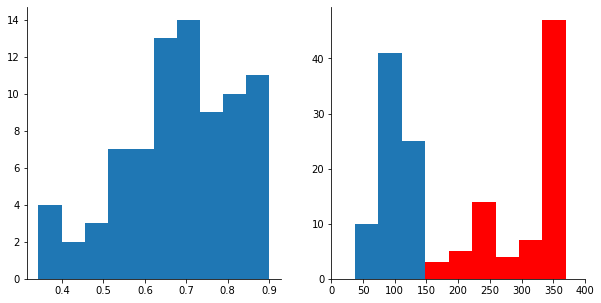

In [344]:
# get mean population lengths (i.e. DSIs) for each cell, and FWHM

imp.reload(ssiMod)
good_idxs = exp_idx_arr[mse_arr<=thr]
# print(good_idxs)
# good_idxs = exp_idx_arr[mse_arr<=thr]
dsi_arr = np.array([])
fwhm_arr = np.array([])
fwhm_arr_narrow = np.array([])


for experiment_number in range(1,8,1):
    final_accepted_cell_idx = []
    experiment_name = f'Exp{experiment_number}'
    datanfits = dict(np.load(main_dir+f'Analysis of {experiment_name}.npz'))
#     print(datanfits.keys())
    good_idx = good_idxs[good_idxs[:,0]==experiment_number, 1]
    mean_tcs = datanfits['mean_tcs'][good_idx]
    fit_tcs = datanfits['ftvm_fit_real_data'][good_idx]
    fit_pars = datanfits['ftvm_fit_parameters'][good_idx]
    
    outlier = np.around(ssiMod.MEAN_RES_LENGTH(stim, fit_tcs, fit_pars[:,1],1), 3)
    
    c_s = np.array([(np.sum(el*np.cos(np.deg2rad(stim)))/np.sum(el), np.sum(el*np.sin(np.deg2rad(stim)))/np.sum(el)) for el in mean_tcs])
    r = np.around(np.sqrt(np.sum(c_s**2, axis = 1)), 3)
    dsi_arr = np.concatenate((dsi_arr, r)) if dsi_arr.size else r
    
    fwhm_arr = np.concatenate((fwhm_arr, np.array([ssiMod.FWHM(el) for el in fit_pars]))) if fwhm_arr.size \
                                    else np.array([ssiMod.FWHM(el) for el in fit_pars])
    fit_pars[:,2] *= 
    fwhm_arr_narrow = np.concatenate((fwhm_arr_narrow, np.array([ssiMod.FWHM(el) for el in fit_pars]))) if fwhm_arr_narrow.size \
                                                  else np.array([ssiMod.FWHM(el) for el in fit_pars])

fig = plt.figure(figsize = (10,5))    
gs = gridspec.GridSpec(1,2)
ax = fig.add_subplot(gs[0,0])
ax1 = fig.add_subplot(gs[0,1])

ax1.set_xlim(0,400)
ax.hist(dsi_arr[dsi_arr>0.3])
ax1.hist(fwhm_arr[:,1][dsi_arr>0.3],range=(0,370))
ax1.hist(fwhm_arr_narrow[:,1][dsi_arr>0.3],range=(0,370), color = 'red')


In [1038]:
print(np.where(np.all(exp_idx_arr==np.array([2,3]), axis = 1))[0])
print(dsi_arr[np.where(np.all(exp_idx_arr==np.array([2,3]), axis = 1))[0]])
print(mse_arr[np.where(np.all(exp_idx_arr==np.array([2,3]), axis = 1))[0]])
print(all_fwhm[:,1][np.where(np.all(exp_idx_arr==np.array([2,3]), axis = 1))[0]])

[20]
[0.474]
[2.7591698]
[202.]


In [1043]:
bad_tc_idx = np.unique(np.concatenate((np.where(mse_arr>=3.5)[0], np.where(dsi_arr<=0.3)[0], np.where(all_fwhm>200)[0])))
print(bad_tc_idx.shape)
good_tc_idx = np.setdiff1d(np.arange(len(all_data)), bad_tc_idx)
print(good_tc_idx)
all_datanfits = dict(np.load(main_dir+'All_datanfits.npz'))
all_datanfits['good_cell_idxs'] = good_tc_idx
np.savez(main_dir+'All_datanfits.npz', **all_datanfits)

(8,)
[ 0  1  2  4  5  6  8  9 10 11 12 14 15 16 17 18 19 21 22 23 24 25 26 28
 29 31 32 33 34 35 36 37 38 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54
 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 75 76 77 78 79
 80 81 82 83 84 85 86 87 88 89]


(array([ 1.,  0.,  4.,  5.,  6.,  8., 18., 12., 15., 12.]),
 array([0.202 , 0.2718, 0.3416, 0.4114, 0.4812, 0.551 , 0.6208, 0.6906,
        0.7604, 0.8302, 0.9   ]),
 <BarContainer object of 10 artists>)

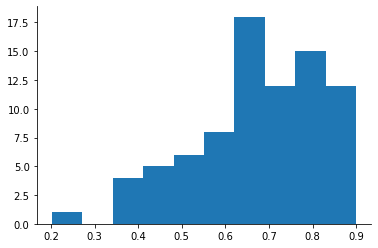

In [220]:
good_idxs = exp_idx_arr
# print(good_idxs)
good_idxs = exp_idx_arr[mse_arr<=thr]
dsi_arr = np.array([])
for experiment_number in range(1,8,1):
    final_accepted_cell_idx = []
    experiment_name = f'Exp{experiment_number}'
    datanfits = dict(np.load(main_dir+f'Analysis of {experiment_name}.npz'))
#     print(datanfits.keys())
    good_idx = good_idxs[good_idxs[:,0]==experiment_number, 1]
    mean_tcs = datanfits['mean_tcs'][good_idx]
    fit_tcs = datanfits['ftvm_fit_real_data'][good_idx]
    fit_pars = datanfits['ftvm_fit_parameters'][good_idx]
    
    outlier = np.around(ssiMod.MEAN_RES_LENGTH(stim, fit_tcs, fit_pars[:,1],1), 3)
    
    c_s = np.array([(np.sum(el*np.cos(np.deg2rad(stim)))/np.sum(el), np.sum(el*np.sin(np.deg2rad(stim)))/np.sum(el)) for el in mean_tcs])
    r = np.around(np.sqrt(np.sum(c_s**2, axis = 1)), 3)
    dsi_arr = np.concatenate((dsi_arr, r)) if dsi_arr.size else r
plt.hist(dsi_arr)

[[ 1 13]]


(array([ 1.,  0.,  7.,  5., 10.,  8., 19., 13., 15., 12.]),
 array([0.202 , 0.2718, 0.3416, 0.4114, 0.4812, 0.551 , 0.6208, 0.6906,
        0.7604, 0.8302, 0.9   ]),
 <BarContainer object of 10 artists>)

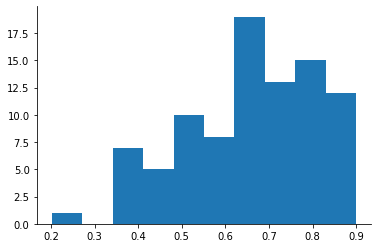

In [216]:
print(exp_idx_arr[dsi_arr<0.3])



9
[[ 1  0]
 [ 1  3]
 [ 1  7]
 [ 2  7]
 [ 3  0]
 [ 3  3]
 [ 3 10]
 [ 3 12]
 [ 6  8]]


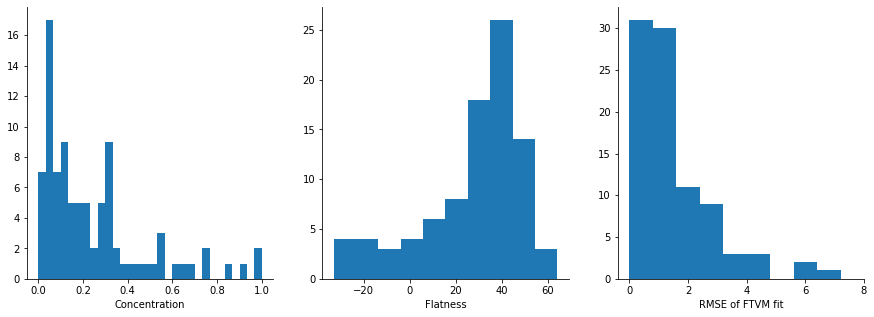

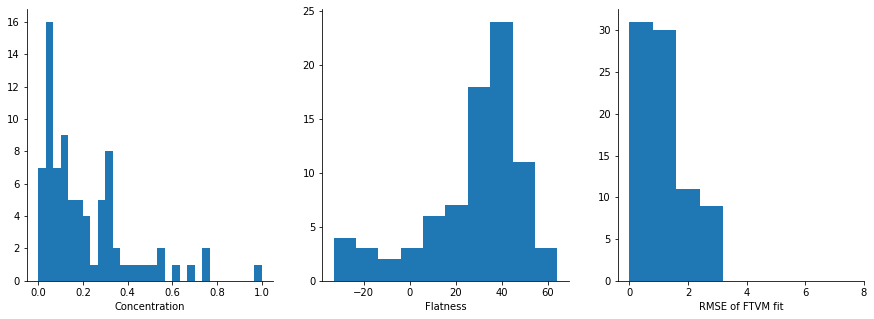

In [204]:
fig = plt.figure(figsize = (15,5))
gs = gridspec.GridSpec(1,3)

ax = fig.add_subplot(gs[0,0])
ax1 = fig.add_subplot(gs[0,1])
ax2 = fig.add_subplot(gs[0,2])
    
ax.hist(s_arr, bins = 30,range=(0,1))
ax1.hist(g_arr)
a = ax2.hist(mse_arr, range=(0,8))
ax.set_xlabel('Concentration')
ax1.set_xlabel('Flatness')
ax2.set_xlabel('RMSE of FTVM fit')
ax2.set_xlim(right=8)


thr = 3

fig = plt.figure(figsize = (15,5))
gs = gridspec.GridSpec(1,3)

ax = fig.add_subplot(gs[0,0])
ax1 = fig.add_subplot(gs[0,1])
ax2 = fig.add_subplot(gs[0,2])
    
ax.hist(s_arr[mse_arr<=thr], bins = 30,range=(0,1))
ax1.hist(g_arr[mse_arr<=thr])
a = ax2.hist(mse_arr[mse_arr<=thr], range=(0,8))
ax.set_xlabel('Concentration')
ax1.set_xlabel('Flatness')
ax2.set_xlabel('RMSE of FTVM fit')
ax2.set_xlim(right=8)

# plt.savefig(dat_dir_out+f'ParamHists_AllExps_{upper_s_lim}.pdf', bbox_inches = 'tight')
print(np.sum(mse_arr>=thr))
print(exp_idx_arr[mse_arr>=thr])




#     plt.scatter(datanfits['ftvm_fit_parameters'][:,2], datanfits['ftvm_fit_parameters'][:,-1], s =2)
#     plt.xlabel(r'Concentration s')
#     plt.ylabel(r'Flatness g')
    
#     if to_save:
#         np.savez(dat_dir+'Analysis of '+experiment_name+'.npz', **datanfits)
#         ssiMod.COPY_CURRENT_NB(raw_data_dir, 'TC Fits and Errors + Compute SSIs')

[  5.           5.           5.           5.           5.
   5.           5.           5.           5.           5.
   5.           5.           5.           5.           5.
   5.           5.           5.           5.           5.
   5.           5.           5.           5.           5.
   5.           5.           5.           5.           5.
   5.           5.           5.           5.           5.
   5.93161115 503.1367777    5.93161115   5.           5.
   5.           5.           5.           5.           5.
   5.           5.           5.           5.           5.
   5.           5.           5.           5.           5.
   5.           5.           5.           5.           5.
   5.           5.           5.           5.           5.
   5.           5.           5.           5.           5.
   5.           5.        ]


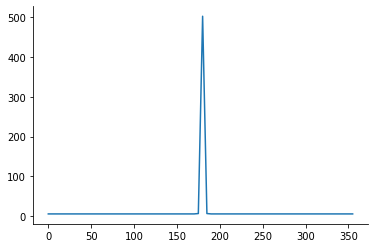

In [119]:
stim = np.arange(0, 360, 5)

a = 500
m = 180
s = 1e-5
b = 5
g = 50

def F(stim, a,m,s,b,g):
    m1 = a*np.exp((np.cos(np.deg2rad(stim-m - g*np.sin(np.deg2rad(stim-m))))-1)/s)
    res = m1/np.sum(m1/a) + b
    return res

print(F(stim, a,m,s,b,g))

plt.plot(stim, F(stim, a,m,s,b,g))
